# Test-set overview (atmomaccs)

Composition of the atmomaccs test pool analysed in `feature_difficulty_analysis_ddp.ipynb`, split by
originating dataset. This uses the **non-deduplicated** spectra in `data/neims/atmomaccs_new`
(9,375 spectra), so a molecule that appears in two sources counts in both. The test split itself
(`combined_atmomaccs_test`, 7,536 spectra) drops the 1,839 repeated InChIKeys.

Panels: (a) functional groups (ATMOMACCS v5 ATMO keys), (b) heavy-atom count, (c) elemental composition class.

Run with the `diffms_lumi` kernel.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger

sys.path.insert(0, '../src')
from ATMOMACCS_no_binary import pyGenATMOKeys

RDLogger.DisableLog('rdApp.*')

## Theme

In [2]:
FONT_FAMILY = 'DejaVu Sans'    # e.g. 'Arial' if installed
FONT_SIZE   = 9                # pt
FIG_SIZE    = (7.2, 3.6)       # inches; double column is about 7.0-7.5 in wide
DPI         = 300
BAR_HEIGHT  = 0.55
EDGE_COLOR  = 'white'          # thin gap between stacked segments
EDGE_WIDTH  = 0.75
CATEGORICAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
OTHER_COLOR = '#b4b4b0'        # for the 'Other' category
SEQUENTIAL  = ['#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']   # light -> dark
OUT_FILE    = 'figs/test_set_overview'   # saved as .pdf and .png
TITLE_LOC = 'left'   # 'left', 'center' or 'right'
TITLE_PAD = 6        # gap between title and top of the axes, in points

plt.rcParams.update({
    'font.family': FONT_FAMILY, 'font.size': FONT_SIZE,
    'axes.titlesize': FONT_SIZE + 1, 'axes.labelsize': FONT_SIZE,
    'xtick.labelsize': FONT_SIZE, 'ytick.labelsize': FONT_SIZE, 'legend.fontsize': FONT_SIZE - 1,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlelocation': TITLE_LOC,
    'axes.titlepad': TITLE_PAD,
    'axes.titleweight': 'bold',
})

## Data and categories

In [3]:
LABELS_FILE = '../data/neims/atmomaccs_new/mist_inputs/labels.tsv'

# spec-name prefix -> display name; this order is the bar order (top to bottom)
SOURCES = {'wang': 'Wang', 'li': 'Li', 'ferraz-caetano': 'Ferraz-Caetano', 'kruger-confined': 'Krüger (confined)'}

# Functional group -> ATMO key names (notebooks/explained_atmo_patterns_v5.csv). A group is present
# if any of its keys matches. Keep at most 8 named groups plus 'Other' (colours run out after that).
FUNCTIONAL_GROUPS = {
    'C=C':             ['C=C (non-aromatic)'],
    'Aromatic ring':   ['aromatic ring'],
    'Hydroxyl':        ['hydroxyl (alkyl)', 'aromatic hydroxyl'],
    'Carbonyl':        ['ketone', 'aldehyde'],
    'Carboxylic acid': ['carboxylic acid'],
    'Ester':           ['ester, all'],
    'Peroxide':        ['peroxide', 'hydroperoxide', 'carbonylperoxyacid'],
    'Nitrate or nitro': ['nitrate', 'carbonylperoxynitrate', 'peroxy nitrate', 'nitro', 'nitrophenol', 'nitroester'],
    'Other':           ['ether', 'ether, aromatic', 'ether (alicyclic)', 'amine, primary', 'amine, secondary',
                        'amine, tertiary', 'amine, aromatic', 'amide', 'organosulfate'],
}

HA_BINS   = [0, 5, 10, 15, 20, 30, np.inf]     # heavy-atom bin edges (right-inclusive)
HA_LABELS = ['1–5', '6–10', '11–15', '16–20', '21–30', '>30']

ELEMENT_CLASSES = ['CH', 'CHO', 'CHN', 'CHON', 'S-containing', 'Halogenated', 'Other']

In [4]:
ATMO_NAMES = pd.read_csv('explained_atmo_patterns_v5.csv', index_col=0)['Name'].tolist()


HALOGENS = {'F', 'Cl', 'Br', 'I'}


def element_class(mol):
    """CH / CHO / CHN / CHON; any F/Cl/Br/I -> 'Halogenated', else any S -> 'S-containing';
    any element besides C, H, O, N, S and halogens (P, metals) -> 'Other'."""
    elements = {a.GetSymbol() for a in mol.GetAtoms()} - {'C', 'H'}
    if elements - {'O', 'N', 'S'} - HALOGENS:
        return 'Other'
    if elements & HALOGENS:
        return 'Halogenated'
    if 'S' in elements:
        return 'S-containing'
    return 'CH' + ''.join(e for e in 'ON' if e in elements)


def functional_groups(mol):
    """True/False per functional group in FUNCTIONAL_GROUPS."""
    keys = dict(zip(ATMO_NAMES, pyGenATMOKeys(mol)))
    return {group: any(keys[k] > 0 for k in names) for group, names in FUNCTIONAL_GROUPS.items()}


df = pd.read_csv(LABELS_FILE, sep='\t')
df['source'] = df['spec'].str.replace(r'_\d+$', '', regex=True).map(SOURCES)
mols = [Chem.MolFromSmiles(s) for s in df['smiles']]
df['heavy_atoms']   = [m.GetNumHeavyAtoms() for m in mols]
df['ha_bin']        = pd.cut(df['heavy_atoms'], HA_BINS, labels=HA_LABELS)
df['element_class'] = [element_class(m) for m in mols]
fg = pd.DataFrame([functional_groups(m) for m in mols])

df.groupby('source').agg(spectra=('spec', 'size'), unique_inchikeys=('inchikey', 'nunique'),
                         median_heavy_atoms=('heavy_atoms', 'median')).reindex(SOURCES.values())

,spectra,unique_inchikeys,median_heavy_atoms
source,,,
Wang,3414,3403,11.0
Li,2206,2156,11.0
Ferraz-Caetano,2407,2293,10.0
Krüger (confined),1348,1348,9.0


## Plot helpers

In [5]:
def to_percent(counts):
    """Row-normalise a (source x category) count table to percent, in SOURCES order."""
    counts = counts.reindex(SOURCES.values())
    return counts.div(counts.sum(axis=1), axis=0) * 100


def composition(col, order):
    """Percent of molecules per category of `col`, per source."""
    return to_percent(pd.crosstab(df['source'], df[col]).reindex(columns=order, fill_value=0))


def stacked_hbar(ax, pct, colors, title, xlabel, legend_ncol=2, title_x=0):
    """One 100 % stacked horizontal bar per source, legend below the panel."""
    pct = pct.iloc[::-1]   # barh draws bottom-up; flip so the first source is on top
    left = np.zeros(len(pct))
    for cat, color in zip(pct.columns, colors):
        ax.barh(pct.index, pct[cat], left=left, height=BAR_HEIGHT, color=color,
                edgecolor=EDGE_COLOR, linewidth=EDGE_WIDTH, label=cat)
        left += pct[cat].to_numpy()
    ax.set(xlim=(0, 100), xlabel=xlabel)
    ax.set_title(title, x=title_x)
    ax.tick_params(axis='y', length=0)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=legend_ncol, frameon=False,
              handlelength=1, columnspacing=1)

## Figure

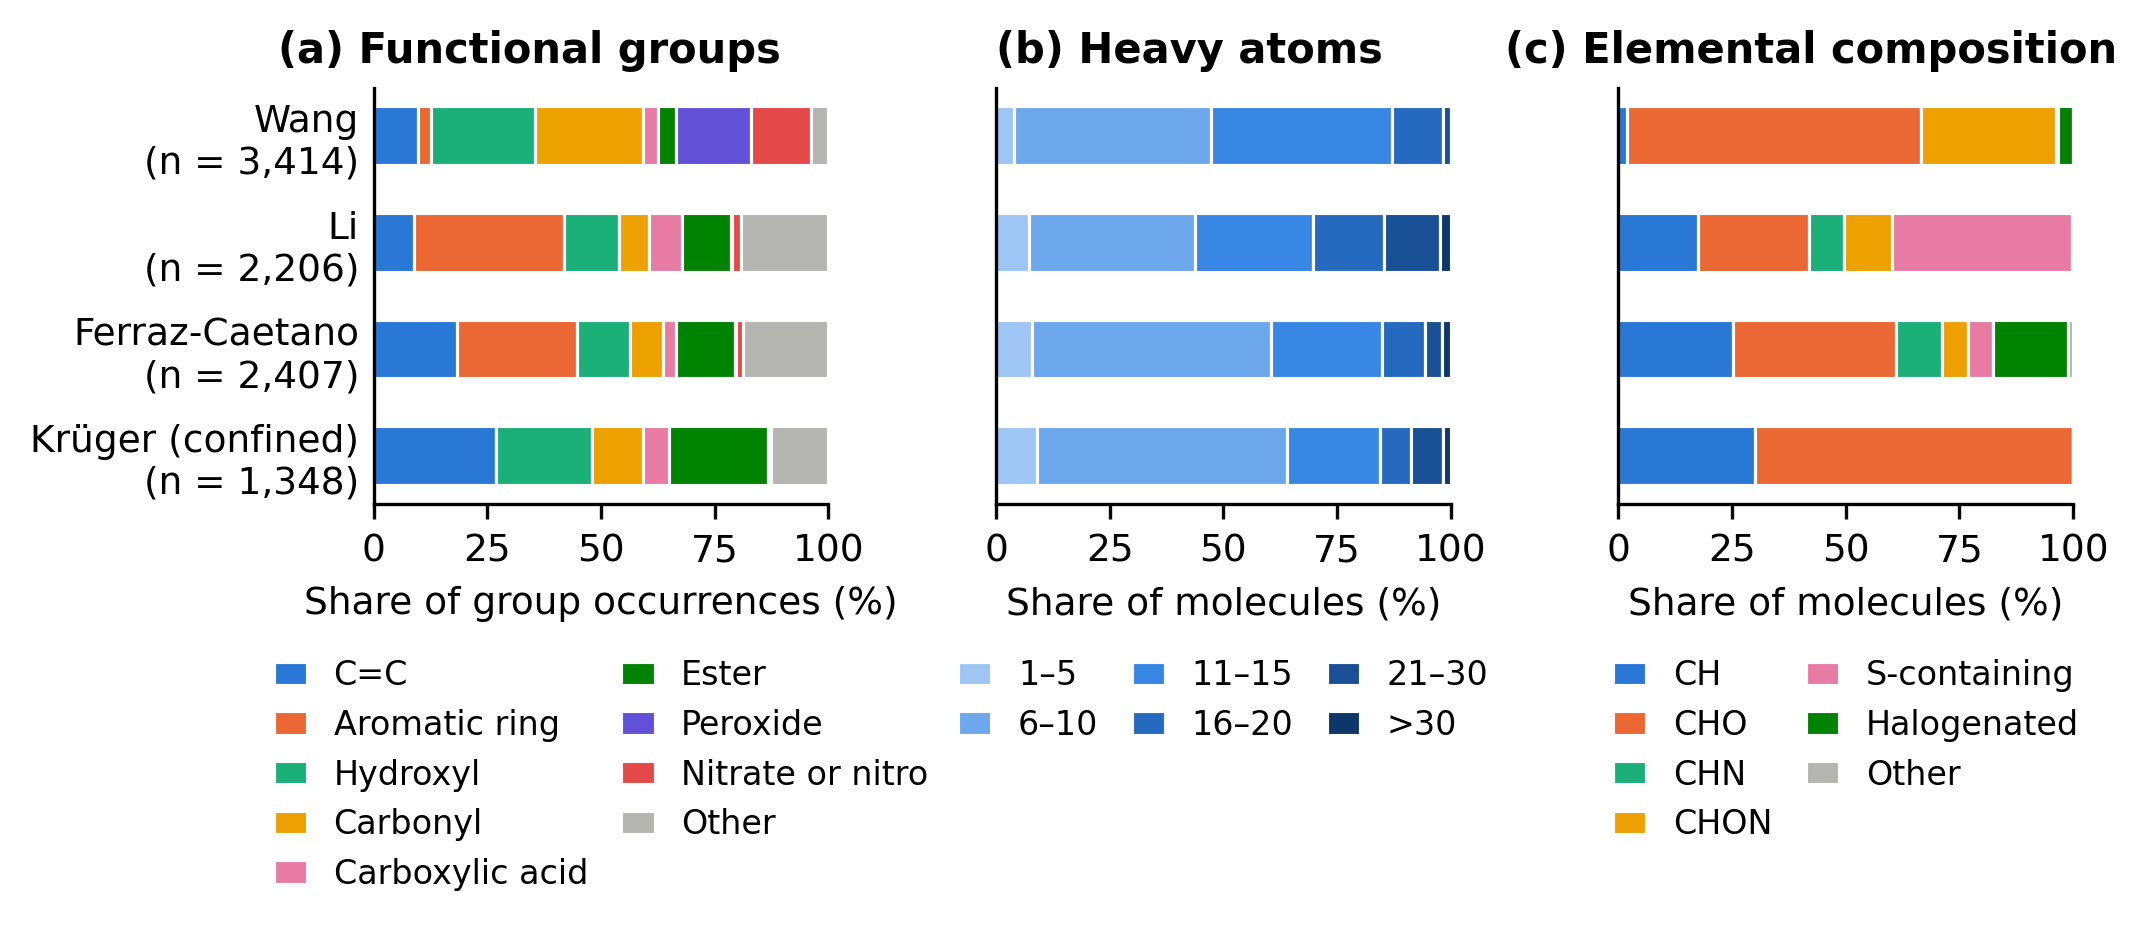

In [6]:
fg_pct = to_percent(fg.groupby(df['source']).sum())   # share of all functional-group occurrences
ha_pct = composition('ha_bin', HA_LABELS)
el_pct = composition('element_class', ELEMENT_CLASSES)

n = df['source'].value_counts()
ylabels = [f'{s}\n(n = {n[s]:,})' for s in SOURCES.values()]

fig, axes = plt.subplots(1, 3, figsize=FIG_SIZE, dpi=DPI, sharey=True)
stacked_hbar(axes[0], fg_pct, CATEGORICAL[:len(FUNCTIONAL_GROUPS) - 1] + [OTHER_COLOR],
             '(a) Functional groups', 'Share of group occurrences (%)', title_x=-0.21)
stacked_hbar(axes[1], ha_pct, SEQUENTIAL, '(b) Heavy atoms', 'Share of molecules (%)', legend_ncol=3, title_x=-0.0)
stacked_hbar(axes[2], el_pct, CATEGORICAL[:len(ELEMENT_CLASSES) - 1] + [OTHER_COLOR],
             '(c) Elemental composition', 'Share of molecules (%)', title_x=-0.25)
axes[0].set_yticks(range(len(ylabels)), ylabels[::-1])

fig.tight_layout()
fig.savefig(f'{OUT_FILE}.pdf', bbox_inches='tight')
fig.savefig(f'{OUT_FILE}.png', bbox_inches='tight')
plt.show()

In [7]:
# Numbers behind the panels
pd.concat({'functional groups': fg_pct, 'heavy atoms': ha_pct, 'elements': el_pct}, axis=1).round(1).T

source                              Wang    Li  Ferraz-Caetano  \
functional groups C=C                9.7   8.9            18.3   
                  Aromatic ring      2.9  33.0            26.4   
                  Hydroxyl          22.8  12.0            11.6   
                  Carbonyl          23.8   6.6             7.4   
                  Carboxylic acid    3.4   7.5             2.7   
                  Ester              3.9  10.7            13.0   
                  Peroxide          16.5   0.1             0.3   
                  Nitrate or nitro  13.2   2.1             1.6   
                  Other              3.8  19.2            18.7   
heavy atoms       1–5                4.0   7.2             8.0   
                  6–10              43.3  36.6            52.6   
                  11–15             39.7  25.9            24.4   
                  16–20             11.2  15.6             9.5   
                  21–30              1.7  12.2             3.7   
                  >30                0.0   2.4             2.0   
elements          CH                 1.8  17.6            25.3   
                  CHO               64.6  24.3            35.8   
                  CHN                0.0   7.7            10.2   
                  CHON              29.7  10.5             5.7   
                  S-containing       0.4  39.5             5.4   
                  Halogenated        3.4   0.3            16.5   
                  Other              0.0   0.0             1.2   

source                              Krüger (confined)  
functional groups C=C                            26.9  
                  Aromatic ring                   0.0  
                  Hydroxyl                       21.2  
                  Carbonyl                       11.2  
                  Carboxylic acid                 5.6  
                  Ester                          21.9  
                  Peroxide                        0.6  
                  Nitrate or nitro                0.0  
                  Other                          12.6  
heavy atoms       1–5                             9.0  
                  6–10                           55.1  
                  11–15                          20.4  
                  16–20                           6.8  
                  21–30                           7.1  
                  >30                             1.6  
elements          CH                             30.1  
                  CHO                            69.9  
                  CHN                             0.0  
                  CHON                            0.0  
                  S-containing                    0.0  
                  Halogenated                     0.0  
                  Other                           0.0

## What is in 'Halogenated' and 'Other'?

'Halogenated' holds every molecule with F, Cl, Br or I, and 'Other' every molecule with an element
outside C, H, O, N, S and the halogens (P, metals). Both rules come before the S rule, so an
S-containing molecule with a halogen or P is counted there. Below, these molecules are split by
(a) the extra elements and (b) their backbone class, i.e. the class they would get with the extra
elements ignored (CH + Cl is a chlorinated hydrocarbon).

In [8]:
EXTRA_GROUPS = ['Cl', 'F', 'Br', 'I', 'Mixed halogens', 'P (± halogen)', 'Metal / other']   # bar order
BACKBONE_CLASSES = ['CH', 'CHO', 'CHN', 'CHON', 'S-containing']


def extra_elements(mol):
    """Elements outside C, H, O, N, S."""
    return {a.GetSymbol() for a in mol.GetAtoms()} - {'C', 'H', 'O', 'N', 'S'}


def extra_group(extra):
    """Single halogen, mixed halogens, any P, or anything else (e.g. metal counter-ions)."""
    if 'P' in extra:
        return 'P (± halogen)'
    if extra - HALOGENS:
        return 'Metal / other'
    return extra.pop() if len(extra) == 1 else 'Mixed halogens'


def backbone_class(mol):
    """element_class with the elements outside C, H, O, N, S ignored."""
    elements = {a.GetSymbol() for a in mol.GetAtoms()} & {'O', 'N', 'S'}
    return 'S-containing' if 'S' in elements else 'CH' + ''.join(e for e in 'ON' if e in elements)


extra = df[df['element_class'].isin(['Halogenated', 'Other'])].copy()
extra_mols = [mols[i] for i in extra.index]
extra['extra']    = [', '.join(sorted(extra_elements(m))) for m in extra_mols]
extra['group']    = [extra_group(extra_elements(m)) for m in extra_mols]
extra['backbone'] = [backbone_class(m) for m in extra_mols]

for cls, n in extra['element_class'].value_counts().items():
    print(f"'{cls}': {n:,} of {len(df):,} spectra ({n/len(df):.1%})")

# Exact extra-element combinations per source
combos = pd.crosstab(extra['extra'], extra['source'], margins=True, margins_name='Total')
combos = combos.reindex(columns=[*SOURCES.values(), 'Total'], fill_value=0)
display(pd.concat([combos.drop('Total').sort_values('Total', ascending=False), combos.loc[['Total']]]))

# Extra-element group x backbone class
display(pd.crosstab(extra['group'], extra['backbone'], margins=True, margins_name='Total')
          .reindex(index=EXTRA_GROUPS + ['Total'], columns=BACKBONE_CLASSES + ['Total'], fill_value=0))

'Halogenated': 519 of 9,375 spectra (5.5%)
'Other': 31 of 9,375 spectra (0.3%)


source,Wang,Li,Ferraz-Caetano,Krüger (confined),Total
extra,,,,,
Cl,104,7,157,0,268
F,0,0,127,0,127
Br,11,0,47,0,58
I,0,0,33,0,33
"Cl, F",0,0,28,0,28
P,0,0,26,0,26
"Br, Cl, F",0,0,3,0,3
"Cl, P",0,0,3,0,3
"Br, F",0,0,2,0,2


backbone,CH,CHO,CHN,CHON,S-containing,Total
group,,,,,,
Cl,130,106,13,18,1,268
F,61,32,24,10,0,127
Br,32,21,4,1,0,58
I,29,3,1,0,0,33
Mixed halogens,22,11,0,0,0,33
P (± halogen),1,14,3,0,12,30
Metal / other,0,1,0,0,0,1
Total,275,188,45,29,13,550


In [9]:
# The 'Other' class: P compounds and metal salts
display(extra[extra['element_class'] == 'Other']
        [['spec', 'source', 'formula', 'extra', 'backbone', 'smiles']].sort_values(['extra', 'formula']))

,spec,source,formula,extra,backbone,smiles
702,ferraz-caetano_702,Ferraz-Caetano,CCl3F2P,"Cl, F, P",CH,C(P(F)F)(Cl)(Cl)Cl
1140,ferraz-caetano_1142,Ferraz-Caetano,C2H6Cl2NP,"Cl, P",CHN,CN(C)P(Cl)Cl
1078,ferraz-caetano_1080,Ferraz-Caetano,C4H12ClN2P,"Cl, P",CHN,CN(C)P(N(C)C)Cl
104,ferraz-caetano_104,Ferraz-Caetano,C4H7Cl2O4P,"Cl, P",CHO,COP(=O)(OC)OC=C(Cl)Cl
3085,li_680,Li,C8H8Na2O5,Na,CHO,[Na+].[Na+].[O-]C(=O)C1C2CCC(O2)C1C([O-])=O
118,ferraz-caetano_118,Ferraz-Caetano,C10H19O6PS2,P,S-containing,CCOC(=O)CC(C(=O)OCC)SP(=S)(OC)OC
1599,ferraz-caetano_1602,Ferraz-Caetano,C10H19O7PS,P,S-containing,CCOC(=O)CC(C(=O)OCC)SP(=O)(OC)OC
1181,ferraz-caetano_1183,Ferraz-Caetano,C12H27O4P,P,CHO,CC(C)COP(=O)(OCC(C)C)OCC(C)C
1244,ferraz-caetano_1247,Ferraz-Caetano,C12H27O4P,P,CHO,CCCCOP(=O)(OCCCC)OCCCC
1227,ferraz-caetano_1230,Ferraz-Caetano,C15H33O4P,P,CHO,CCCCCOP(=O)(OCCCCC)OCCCCC


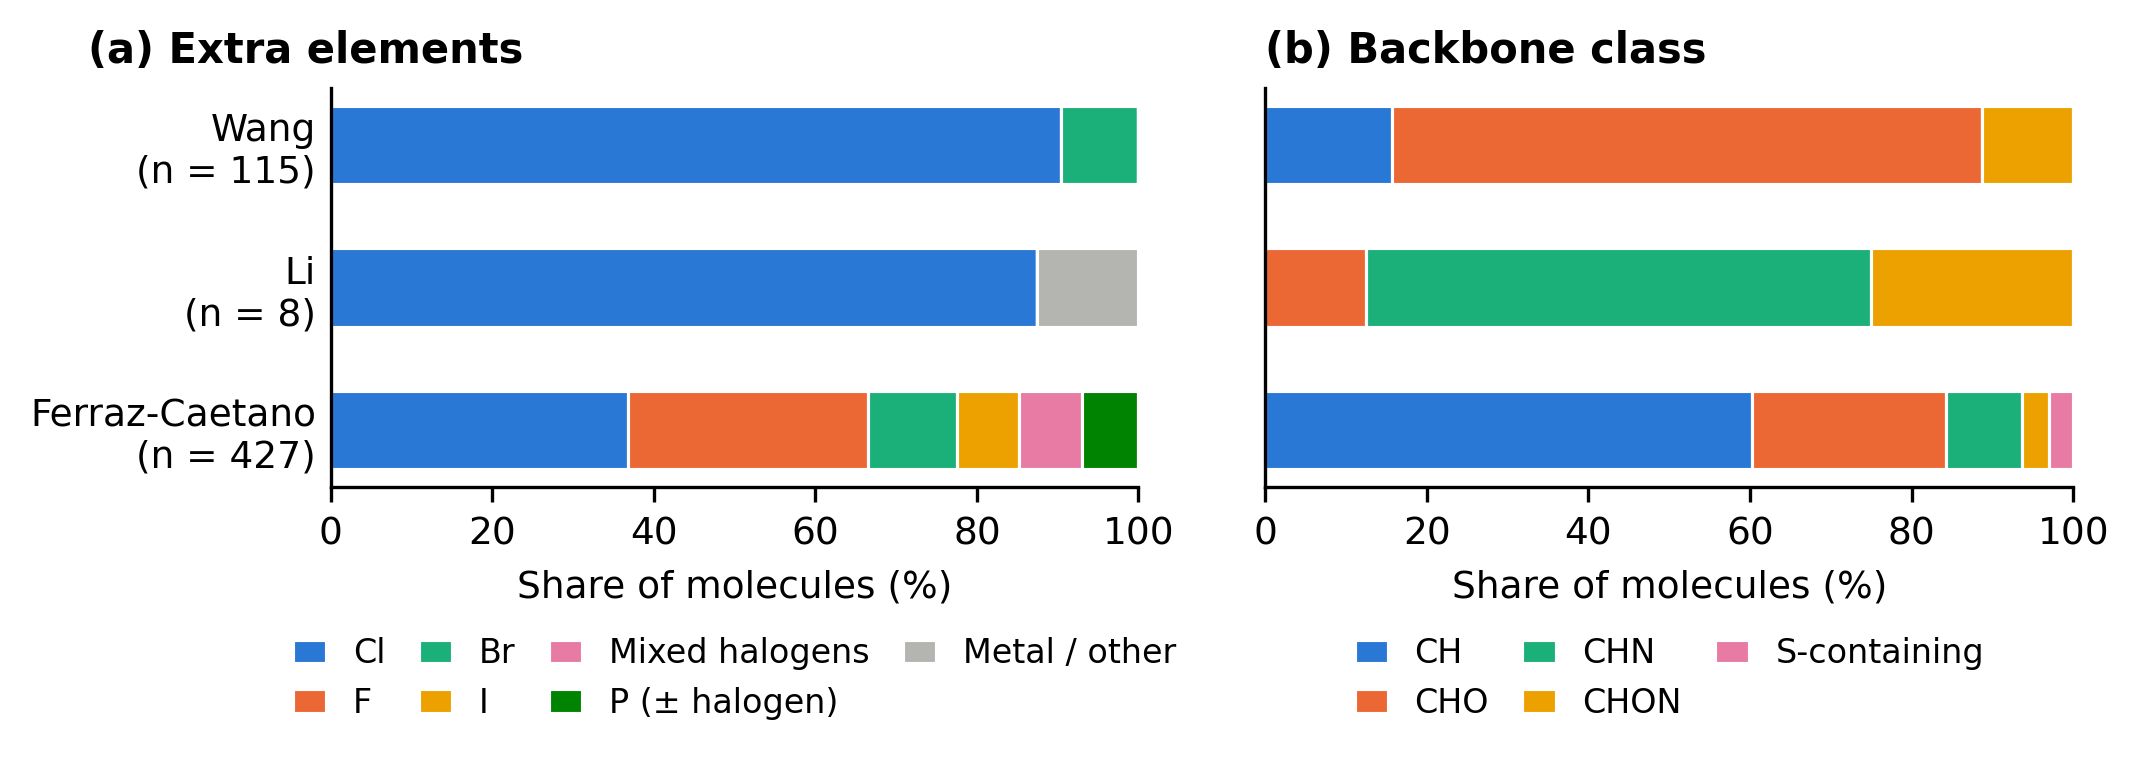

In [10]:
# Sources without such molecules are left out
grp_pct = to_percent(pd.crosstab(extra['source'], extra['group']).reindex(columns=EXTRA_GROUPS, fill_value=0)).dropna()
bb_pct  = to_percent(pd.crosstab(extra['source'], extra['backbone']).reindex(columns=BACKBONE_CLASSES, fill_value=0)).dropna()

n_extra = extra['source'].value_counts()
ylabels = [f'{s}\n(n = {n_extra[s]:,})' for s in grp_pct.index]

fig, axes = plt.subplots(1, 2, figsize=(FIG_SIZE[0], FIG_SIZE[1] * 0.8), dpi=DPI, sharey=True)
stacked_hbar(axes[0], grp_pct, CATEGORICAL[:len(EXTRA_GROUPS) - 1] + [OTHER_COLOR],
             '(a) Extra elements', 'Share of molecules (%)', legend_ncol=4, title_x=-0.3)
stacked_hbar(axes[1], bb_pct, CATEGORICAL[:len(BACKBONE_CLASSES)],
             '(b) Backbone class', 'Share of molecules (%)', legend_ncol=3)
axes[0].set_yticks(range(len(ylabels)), ylabels[::-1])

fig.tight_layout()
fig.savefig(f'{OUT_FILE}_halogenated_other.pdf', bbox_inches='tight')
fig.savefig(f'{OUT_FILE}_halogenated_other.png', bbox_inches='tight')
plt.show()